# 128. Longest Consecutive Sequence
**Difficulty:** 🟡 Medium · **Topic:** Arrays and Hashing · **Pattern:** [Hash Lookup](README.md) · **LeetCode:** https://leetcode.com/problems/longest-consecutive-sequence/

## 💡 Concepts

**Core concept(s):** A **hash set** for instant membership, so you can grow each run from its start.

**Why it applies here:** Numbers that follow each other (like 1,2,3,4) form a chain. Put everything in a set; only start counting a run at a number whose predecessor is missing (a true start), then walk upward. Each number is visited about once overall → linear.

**Key intuition:** Only begin counting at the first number of a run, then step up one at a time while the next exists.

---

### 📚 What is a Hash Set?
A `set` answers "is x here?" in **O(1)** average. Here it lets us test membership (e.g. "is x-1 present?") without scanning.

---

**Prerequisite knowledge:**
- A `set` for O(1) membership.
- Recognizing a run's starting point (`x-1` absent).

## 📝 Problem

Given an unsorted array, return the length of the longest run of consecutive integers. Must be `O(n)`.

**Example**
```
[100,4,200,1,3,2] -> 4    (1,2,3,4)
```

> Two approaches: sort `O(n log n)` and hash set `O(n)`.

### Approach 1 — Sort, Then Scan (worst)

**Idea:** Sort the unique values; count runs where each value is one more than the last.

**Time:** `O(n log n)`. **Space:** `O(n)`.

In [1]:
def longest_consec_sort(nums):
    if not nums:
        return 0
    s = sorted(set(nums))                  # unique values in order
    best = cur = 1
    for i in range(1, len(s)):
        if s[i] == s[i-1] + 1:             # continues the current run
            cur += 1; best = max(best, cur)
        else:
            cur = 1                        # gap -> start a new run
    return best

### Approach 2 — Hash Set, Grow From Starts (optimal)

**Idea:** Put all numbers in a set. Only start a run at `x` when `x-1` is absent, then count `x+1, x+2, ...`. Each number is touched about once.

**Time:** `O(n)`. **Space:** `O(n)`.

In [2]:
def longest_consec_set(nums):
    numset = set(nums)                     # O(1) membership tests
    best = 0
    for x in numset:
        if x - 1 not in numset:            # x is the START of a run (nothing comes before it)
            length = 1
            while x + length in numset:    # walk forward while the next number exists
                length += 1
            best = max(best, length)
    return best                            # each number is visited at most once overall

In [3]:
# Correctness check
tests = [([100,4,200,1,3,2],4), ([0,3,7,2,5,8,4,6,0,1],9), ([],0), ([5,5,5],1)]
for nums, exp in tests:
    a, b = longest_consec_sort(nums), longest_consec_set(nums)
    print(f"{nums} -> sort={a}, set={b} | expected={exp}")
    assert a == b == exp, "mismatch!"
print("\nAll tests passed")

[100, 4, 200, 1, 3, 2] -> sort=4, set=4 | expected=4
[0, 3, 7, 2, 5, 8, 4, 6, 0, 1] -> sort=9, set=9 | expected=9
[] -> sort=0, set=0 | expected=0
[5, 5, 5] -> sort=1, set=1 | expected=1

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)` / `O(V+E)` | ≈ **2×** |
| `O(n log n)`      | ≈ **2×** (slightly more) |
| `O(n²)`           | ≈ **4×** |

The input is a run of `n` consecutive numbers in **shuffled** order: the set approach must walk the whole run once, and the sort cannot benefit from already-sorted input (Timsort is `O(n)` on sorted data, which would hide its `n log n`).


sort O(n log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       0.27 |           n/a
     4000 |       0.46 |         1.72x
     8000 |       0.96 |         2.10x
    16000 |       2.04 |         2.12x

set  O(n)      
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     2000 |       0.14 |           n/a
     4000 |       0.27 |         1.90x
     8000 |       0.60 |         2.24x
    16000 |       1.25 |         2.07x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


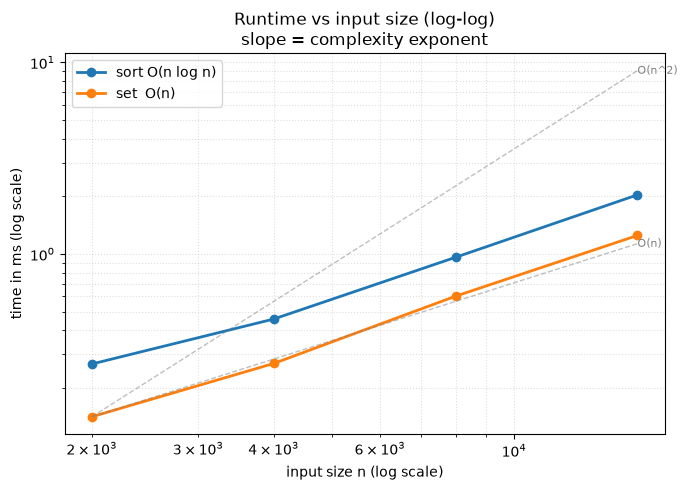

{'sort O(n log n)': [0.2666669897735119,
  0.4576250212267041,
  0.9609159315004945,
  2.035000012256205],
 'set  O(n)      ': [0.1414580037817359,
  0.2683340571820736,
  0.6021669832989573,
  1.2491249945014715]}

In [4]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

import random

def make_worst_case(n):
    nums = list(range(n))      # one long run of n consecutive numbers...
    random.Random(n).shuffle(nums)  # ...in shuffled order, so sorting does real O(n log n) work
    return (nums,)
solutions = {
    "sort O(n log n)": longest_consec_sort,
    "set  O(n)      ": longest_consec_set,
}
sizes = [2000, 4000, 8000, 16000]

benchmark(solutions, make_worst_case, sizes, plot=True)


## 🧩 Patterns Learned

- **Pattern:** [Hash Lookup](README.md) — build the set first, then probe neighbours: `x - 1 not in numset` marks a run's start and `x + length in numset` grows it, each an O(1) lookup.
- **Set membership to avoid sorting:** testing "is the neighbor present?" in O(1) lets you find runs in linear time.
- **Only start at true starts:** the `x-1 not in set` check is what keeps it O(n) (no number is counted twice).
- **Signal:** "longest consecutive / run of numbers", "O(n) without sorting".
- **Related problems:** Longest Increasing Subsequence (different!), Union-Find groupings.
- **Common pitfalls:** (1) counting a run from every element (→ O(n²)); (2) not de-duplicating.